In [17]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
import os
import sys

import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

import src.plotting as plot
import src.utils as utils
from src.config import *

In [19]:
AMOC_ON = "pi/pi-amoc-on"
AMOC_OFF = "pi/pi-amoc-off"

model_ice = "yelmo"

In [20]:
fpath_amoc_on = os.path.join(DIR_OUTPUT, AMOC_ON, "ocn.nc")
fpath_amoc_off = os.path.join(DIR_OUTPUT, AMOC_OFF, "ocn.nc")

DIR_AMOC_CACHE = os.path.join(DIR_DATA, "AMOC")
os.makedirs(DIR_AMOC_CACHE, exist_ok=True)

time_ind = 0
month_ind = 12
fpath_processed = os.path.join(
    DIR_AMOC_CACHE,
    f"amoc_streamfunction_t{time_ind}_m{month_ind}.nc",
)

source_files_available = os.path.isfile(fpath_amoc_on) and os.path.isfile(fpath_amoc_off)

### General AMOC figures

vmin: -7, vmax: 21


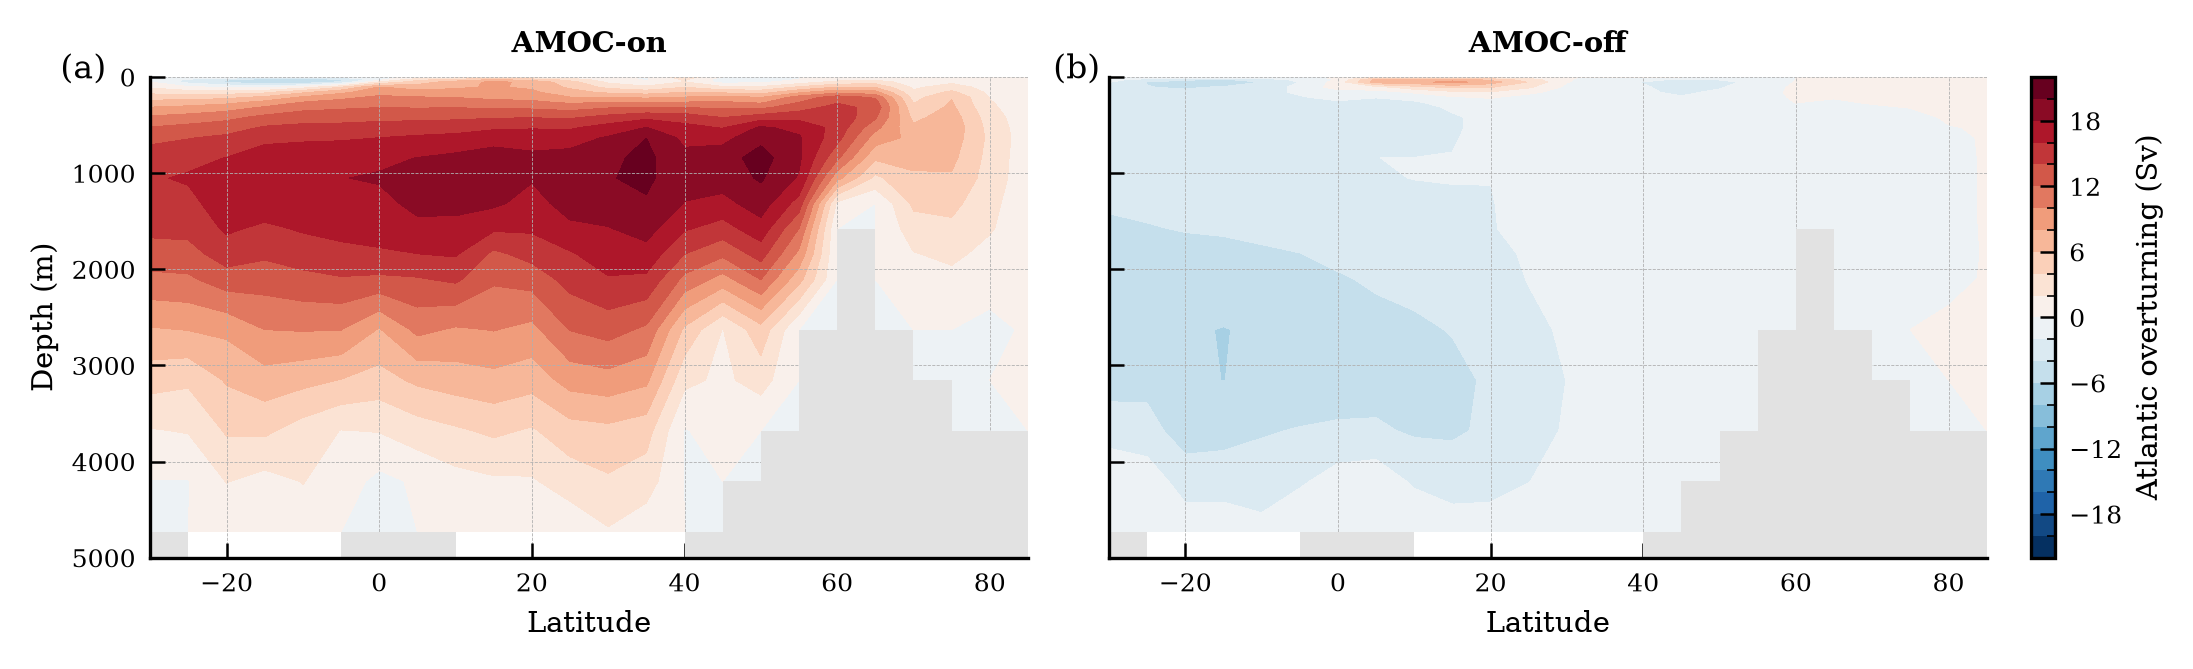

In [21]:
if source_files_available:
    with xr.open_dataset(fpath_amoc_on, mode="r") as ds_ocn_amoc_on, xr.open_dataset(
        fpath_amoc_off, mode="r"
    ) as ds_ocn_amoc_off:
        # Use a_atl for the bathymetry mask (NaN values indicate bathymetry).
        ds_a_atl = ds_ocn_amoc_on["a_atl"].isel(time=time_ind)
        nan_mask = ds_a_atl.isnull()
        ds_mask = xr.where(nan_mask, 1, np.nan)

        ds_ocn_amoc_on_plot = ds_ocn_amoc_on["opsi_a"].isel(
            time=time_ind, month=month_ind
        ).sel(latv1=slice(-30, 85))
        ds_ocn_amoc_off_plot = ds_ocn_amoc_off["opsi_a"].isel(
            time=time_ind, month=month_ind
        ).sel(latv1=slice(-30, 85))

        # Keep the two vertical grids separate; xarray otherwise aligns them
        # onto their coordinate union and inserts all-NaN rows.
        ds_processed = xr.Dataset(
            {
                "amoc_on": ds_ocn_amoc_on_plot.rename(
                    {"levw": "amoc_on_levw", "latv1": "amoc_on_latv1"}
                ),
                "amoc_off": ds_ocn_amoc_off_plot.rename(
                    {"levw": "amoc_off_levw", "latv1": "amoc_off_latv1"}
                ),
                "bathymetry_mask": ds_mask,
            }
        ).load()
        ds_processed.to_netcdf(fpath_processed)
else:
    if not os.path.isfile(fpath_processed):
        raise FileNotFoundError(
            "Neither both source files nor the processed cache are available. "
            f"Expected sources: {fpath_amoc_on} and {fpath_amoc_off}; "
            f"expected cache: {fpath_processed}"
        )
    ds_processed = xr.load_dataset(fpath_processed)
    ds_ocn_amoc_on_plot = ds_processed["amoc_on"]
    ds_ocn_amoc_off_plot = ds_processed["amoc_off"]

    if "amoc_on_levw" in ds_ocn_amoc_on_plot.dims:
        ds_ocn_amoc_on_plot = ds_ocn_amoc_on_plot.rename(
            {"amoc_on_levw": "levw", "amoc_on_latv1": "latv1"}
        )
        ds_ocn_amoc_off_plot = ds_ocn_amoc_off_plot.rename(
            {"amoc_off_levw": "levw", "amoc_off_latv1": "latv1"}
        )
    else:
        # Remove all-NaN levels written by older caches with merged grids.
        ds_ocn_amoc_on_plot = ds_ocn_amoc_on_plot.dropna(dim="levw", how="all")
        ds_ocn_amoc_off_plot = ds_ocn_amoc_off_plot.dropna(dim="levw", how="all")

    ds_mask = ds_processed["bathymetry_mask"]

# Minimum and maximum values for the colorbar.
# Round vmin and vmax to nearest higher absolute integer for better readability.
vmin = utils.round_away_from_zero(min(ds_ocn_amoc_on_plot.min(), ds_ocn_amoc_off_plot.min()).values)
vmax = utils.round_away_from_zero(max(ds_ocn_amoc_on_plot.max(), ds_ocn_amoc_off_plot.max()).values)
print(f"vmin: {vmin}, vmax: {vmax}")

# Center the colorbar around zero.
vmin = -max(abs(vmin), abs(vmax))
vmax = max(abs(vmin), abs(vmax))

# Tweak vmin and vmax by hand to make the colorbar more readable.
vmin = -22
vmax = 22
levels = np.linspace(vmin, vmax, 23)

fig, axs = plot.subplots(ncols=2, figsize=(plot.width_twocol, plot.height_onecol), sharex=True, sharey=True)
ax1, ax2 = axs
ds_ocn_amoc_on_plot.plot.contourf(x="latv1", y="levw", ax=ax1, vmin=vmin, vmax=vmax, cmap="RdBu_r", levels=levels, zorder=1, add_colorbar=False)
ds_mask.plot.pcolormesh(x="lat", y="lev", ax=ax1, cmap="Greys", vmin=0, vmax=5, alpha=1, add_colorbar=False, zorder=2)

ax1.invert_yaxis()
ax1.set_xlim(-30, 85)
ax1.set_ylim(5000, 0)
ax1.set_xlabel("Latitude")
ax1.set_ylabel("Depth (m)")
ax1.set_title("AMOC-on", fontweight="bold", fontsize=7)
ax1.grid()

ds_ocn_amoc_off_plot.plot.contourf(x="latv1", y="levw", ax=ax2, vmin=vmin, vmax=vmax, cmap="RdBu_r", levels=levels, zorder=1, cbar_kwargs={"label": r"Atlantic overturning (Sv)"})
ds_mask.plot.pcolormesh(x="lat", y="lev", ax=ax2, cmap="Greys", vmin=0, vmax=5, alpha=1, add_colorbar=False, zorder=2)

ax2.invert_yaxis()
ax2.set_xlim(-30, 85)
ax2.set_ylim(5000, 0)
ax2.set_xlabel("Latitude")
ax2.set_ylabel(None)
ax2.set_title("AMOC-off", fontweight="bold", fontsize=7)
ax2.grid()

# Add labels (a) and (b)
ax1.text(-0.05, 1.05, "(a)", transform=ax1.transAxes, va="top", ha="right")
ax2.text(-0.01, 1.05, "(b)", transform=ax2.transAxes, va="top", ha="right")

plt.savefig(os.path.join(DIR_FIG, "AMOC_streamfunction_on_off.pdf"), format="pdf")